# 1. The hand construction — all four matrices, in full

Every entry of all four matrices, one per cell, each at its true aspect ratio. Not just the
trainable blocks — so the sparsity is visible.

Constants: $P_1=1000$, $P_2=50$, $\Gamma=-5\times10^{4}$, $\text{BIG}=-10^{9}$, positional
slope $\text{AR}=20$, no cap. These are the *original* magnitudes; §2 reduces them.

**Four things removed from the original, all verified inert** — each was measured, not assumed:

| removed | entries | why it does nothing |
|---|---|---|
| the self-veto **diagonal** of the position block | 100 | the causal mask is `triu(diagonal=0)`, so a position already cannot attend to itself |
| the noise veto on the **position-query rows** | 400 | every query activates one token row *and* one position row, so the veto on `[4:8, 0:8]` already reaches every query — repeating it over the position rows applies it twice |
| everything **above the causal mask** in the position block | 4,950 | $-\text{AR}(t_q-t_k)$ goes *positive* there, reaching $+2.06\times10^{4}$ — and `softmax(s + mask)` discards all of it every forward pass |
| the $+103.92$ **column 4** of the induction block | 8 | a $W_q^\top W_k$ factorisation side effect, 100× below the diagonal, boosting keys already vetoed at $-5.2\times10^{6}$ |

$W_{qk}^{(1)}$: 10,432 → **4,982** nonzeros.  $W_{qk}^{(2)}$: 48 → **40**.
Cross entropy: **1.69978 either way**, at every combination tested.

The noise veto stays in the $8\times8$ token block, where it does the work.

The one thing still original here is the **magnitudes** — $|W_{qk}^{(1)}|_{\max}\approx10^{10}$,
$|W_{qk}^{(2)}|_{\max}\approx5\times10^{6}$. §2 brings those down.

In [ ]:
import os
import json
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import SymLogNorm

RUN = ('runs/master_opt-adam_lr-1.0_init-zeros_wov-fixed_blocks-relevant-strict'
       '_readout-bias_ep-500')
THR = 0.6
V, Vs, T = 8, 4, 100
D1, D2 = V + T, 2 * (V + T)          # 108, 216

# what this run has so far -- the last threshold may still be training
print(f'{RUN}\n')
for _t in (0.6, 0.8, 1.0):
    _f = f'{RUN}/snapmeta_x_{_t}.json'
    if not os.path.exists(_f):
        print(f'  alpha={_t}: not started'); continue
    _m = json.load(open(_f))
    _done = _m['w_rows_written'] >= _m['rows_allocated']
    print(f"  alpha={_t}: w={_m['w_rows_written']}/{_m['rows_allocated']}  "
          f"{'complete' if _done else 'STILL TRAINING -- cells below use what exists'}")
print()

meta = json.load(open(f'{RUN}/snapmeta_x_{THR}.json'))
n    = meta['w_rows_written']
W, MK = {}, {}
for p in meta['params']:
    W[p]  = np.load(f'{RUN}/w_{p}_x_{THR}.npy', mmap_mode='r')[:n]
    MK[p] = np.load(f'{RUN}/mask_{p}_x_{THR}.npy')

def final(p):
    '''the last recorded step, put back into its full matrix'''
    A = np.zeros(meta['shapes'][p]); A[MK[p]] = W[p][-1]
    return A

def heat(ax, A, title, annot=False, fs=6.5, lt=None):
    v = float(np.abs(A).max())
    # default linthresh is v/1e3; pass lt to stop one huge entry flattening everything below it
    nrm = SymLogNorm(linthresh=(lt if lt else max(v/1e3, 1e-30)), linscale=0.6,
                     vmin=-v, vmax=v, base=10) if v > 0 else None
    im = ax.imshow(A, cmap='RdBu_r', interpolation='nearest', norm=nrm)
    if annot:
        for i in range(A.shape[0]):
            for j in range(A.shape[1]):
                ax.text(j, i, f'{A[i, j]:.3g}', ha='center', va='center', fontsize=fs)
        ax.set_xticks(range(A.shape[1])); ax.set_yticks(range(A.shape[0]))
        ax.set_xticklabels([f'k{i}' for i in range(A.shape[1])], fontsize=7)
        ax.set_yticklabels([f'q{i}' for i in range(A.shape[0])], fontsize=7)
        if A.shape[0] > Vs: ax.axhline(Vs - .5, color='k', lw=.8)   # signal | noise
        if A.shape[1] > Vs: ax.axvline(Vs - .5, color='k', lw=.8)
    else:
        ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f'{title}\n|max| {np.abs(A).max():.4g}   '
                 f'$\\|\\cdot\\|_F$ {np.linalg.norm(A):.4g}', fontsize=10)
    return im



# ---- the construction, at its original magnitudes -----------------------------------------
AR, GAMMA, P1, P2, NF, BIG = 20.0, -50000.0, 1000.0, 50.0, 10.0, -1e9
SDq = D1 ** 0.5

def build_original():
    """Original magnitudes, minus the two blocks measured to be inert:
       no self-veto diagonal (the causal mask does it) and no noise veto on position rows."""
    Wq1 = np.eye(D1) * SDq
    T1  = np.zeros((D1, D1))
    T1[Vs:V, :V] = BIG                      # noise-key veto -- TOKEN query rows only
    for tq in range(T):
        for tk in range(T):
            if tq > tk:                         # past keys only; above the mask stays 0
                T1[V+tk, V+tq] = -AR * (tq - tk)
    Wq2 = np.zeros((D1, D2)); Wk2 = np.zeros((D1, D2))
    Wq2[:Vs, :Vs]      = np.eye(Vs) * SDq * P1
    Wq2[:Vs, D1:D1+Vs] = np.eye(Vs) * SDq * P2
    Wq2[Vs, :V]        = SDq * NF
    Wk2[:V, D1:D1+V]   = np.eye(V)
    Wk2[Vs, Vs:V]      = GAMMA
    ov1 = np.zeros((D1, D1)); ov1[0:V, 0:V] = np.eye(V)
    ov2 = np.zeros((D2, D1)); ov2[0:V, 0:V] = np.eye(V)
    C1, C2 = Wq1.T @ T1.T, Wq2.T @ Wk2
    C2[0:V, D1 + Vs] = 0.0                  # the inert +103.92 artefact column
    return C1, C2, ov1, ov2

O1, O2, OV1, OV2 = build_original()

def show(A, title, insets, base=8.5):
    """one matrix, figure sized to its true aspect, with each populated block inset.
       `insets` is a list of (slice_tuple, label, [x, y, w, h] in axes fraction)."""
    rows, cols = A.shape
    fig, ax = plt.subplots(figsize=(base * cols / rows + 2.2, base))
    nzv = np.abs(A[A != 0])
    lt = float(nzv.min()) if nzv.size else None      # smallest real entry, so none are hidden
    im = heat(ax, A, title, lt=lt)
    cb = fig.colorbar(im, ax=ax, fraction=0.045, pad=0.03)
    v = float(np.abs(A).max())
    # symlog auto-ticks collide near zero; and with few distinct values 3 ticks is all that fits
    tk = [-v, 0.0, v] if (lt is None or lt >= v / 10) else [-v, -lt, 0.0, lt, v]
    cb.set_ticks(tk); cb.ax.set_yticklabels([('0' if t == 0 else f'{t:.3g}') for t in tk],
                                            fontsize=8)

    for sl, itl, rect in insets:
        S = A[sl]
        ins = ax.inset_axes(rect)
        vi = float(np.abs(S).max())
        ins.imshow(S, cmap='RdBu_r', interpolation='nearest',
                   norm=SymLogNorm(linthresh=max(vi/1e3, 1e-30), linscale=0.6,
                                   vmin=-vi, vmax=vi, base=10) if vi > 0 else None)
        lab = [['0' if z == 0 else (f'{z:.0f}' if abs(z) < 1e4 else f'{z:.1e}') for z in row]
               for row in S]
        wid = max(len(x) for row in lab for x in row)
        fs = (11.0 if S.shape[0] <= Vs else 7.0) * min(1.0, 5.0 / wid)   # shrink long labels
        for a in range(S.shape[0]):
            for b in range(S.shape[1]):
                ins.text(b, a, lab[a][b], ha='center', va='center', fontsize=fs,
                         fontweight='bold' if a == b else 'normal',
                         color='white' if abs(S[a, b]) > vi / 3 else 'black')
        ins.set_xticks(range(S.shape[1])); ins.set_yticks(range(S.shape[0]))
        ins.set_xticklabels([f'k{q}' for q in range(S.shape[1])], fontsize=8)
        ins.set_yticklabels([f'q{q}' for q in range(S.shape[0])], fontsize=8)
        if S.shape[0] > Vs: ins.axhline(Vs - .5, color='k', lw=.8)
        if S.shape[1] > Vs: ins.axvline(Vs - .5, color='k', lw=.8)
        ins.set_title(itl, fontsize=9.5, pad=3)
        for sp in ins.spines.values():
            sp.set_edgecolor('0.25'); sp.set_linewidth(1.4)

    fig.tight_layout(); plt.show()
    nz = int((A != 0).sum())
    print(f'{title}:  {nz:,} nonzeros of {A.size:,}  ({nz/A.size:.1%})   '
          f'|max| {np.abs(A).max():.4g}')

show(O1, 'layer 1  $W_{qk}$   (108 x 108)',
     [((slice(0, V), slice(0, V)), 'top-left 8x8\ntoken x token', [0.42, 0.40, 0.56, 0.56])])
fut = O1[V:D1, V:D1][np.triu_indices(T, 1)]
print(f'  above the causal mask: {int((fut != 0).sum())} nonzeros -- nothing is filled there')
print(f'  the noise veto sits only in [0:8, 4:8]; the 400 position-row copies are gone')

In [ ]:
show(OV1, 'layer 1  $W_{ov}$   (108 x 108)',
     [((slice(0, V), slice(0, V)), 'top-left 8x8\nthe frozen $I_8$', [0.42, 0.40, 0.56, 0.56])])
print('  the whole matrix is one 8x8 identity. It is what makes f a probability vector:')
print('  attention weights are non-negative and sum to 1, and W_ov copies token one-hots,')
print('  so f is a convex combination of one-hots -- no unembedding, log or softmax needed.')


In [ ]:
# BOTH 4x4 diagonal blocks, zoomed side by side: the induction head (own token x key's
# retrieved state) and the state block (own retrieved state x key's retrieved state)
show(O2, 'layer 2  $W_{qk}$   (216 x 216)',
     [((slice(0, Vs), slice(D1, D1 + Vs)),
       '[0:4, 108:112]\ninduction head\nown token x key state', [0.30, 0.30, 0.31, 0.31]),
      ((slice(D1, D1 + Vs), slice(D1, D1 + Vs)),
       '[108:112, 108:112]\nstate x state\nown state x key state', [0.67, 0.30, 0.31, 0.31])])
ind = O2[0:Vs, D1:D1+Vs]
st  = O2[D1:D1+Vs, D1:D1+Vs]
print(f'  induction diagonal   {ind[0,0]:>10.1f}   off-diagonal {ind[0,1]:.0f}')
print(f'  state x state diag   {st[0,0]:>10.1f}   off-diagonal {st[0,1]:.0f}'
      f'   -- {ind[0,0]/st[0,0]:.0f}x weaker than the induction head')
print('  both say the same thing: prefer the key whose retrieved state matches. The induction')
print('  head compares it against the OWN TOKEN, the state block against the OWN STATE.')
print('  columns and rows 116..216 are identically zero -- layer 1 writes only its first 8 coords')


In [ ]:
show(OV2, 'layer 2  $W_{ov}$   (216 x 108)',
     [((slice(0, V), slice(0, V)), 'top-left 8x8\nthe frozen $I_8$', [0.40, 0.34, 0.56, 0.56])],
     base=9.5)
print('  216 x 108 -- the only non-square matrix here. Same content as layer 1s W_ov:')
print('  one 8x8 identity, frozen, 8 nonzeros in 23,328 entries.')


# 2. The hand construction, reduced-magnitude form

The reference circuit, in the same block layout as §4 so the two are directly comparable.
Full write-up in `weight_handconstruction_current.pdf`.

Logit-level constants $\lambda=20$ (positional slope), $C=5$ (decay cap), $K=100$ (induction
bonus), $B=100$ (veto depth). A $W_{qk}$ entry of size $w$ contributes $w/\sqrt{108}$ to the
attention logit, so every entry below is its logit constant $\times\,\sqrt{108}=10.3923$.

Three things differ from §1, the original construction:

| | old | new |
|---|---|---|
| $\|W_{qk}^{(1)}\|_{\max}$ | 1.04e10 | **1039.2** |
| $\|W_{qk}^{(2)}\|_{\max}$ | 5.20e06 | **1039.2** |
| nonzeros in $W_{qk}^{(2)}$ | 192 | **40** |

1. **Magnitudes** cut to the smallest that still works — costs 0.004 nats (1.70035 vs 1.69622).
2. **The inert column removed.** The old induction block carried $+103.92$ in every row of
   column 4; ablating it changed the CE by exactly 0.00e+00 at every $\alpha$.
3. **The masked-out future entries zeroed.** $-\lambda(t_q-t_k)$ goes *positive* for $t_k>t_q$,
   reaching $+\lambda\cdot 99$ — that is where the old $|max|$ of 20577 came from, on entries the
   causal mask discards every forward pass.

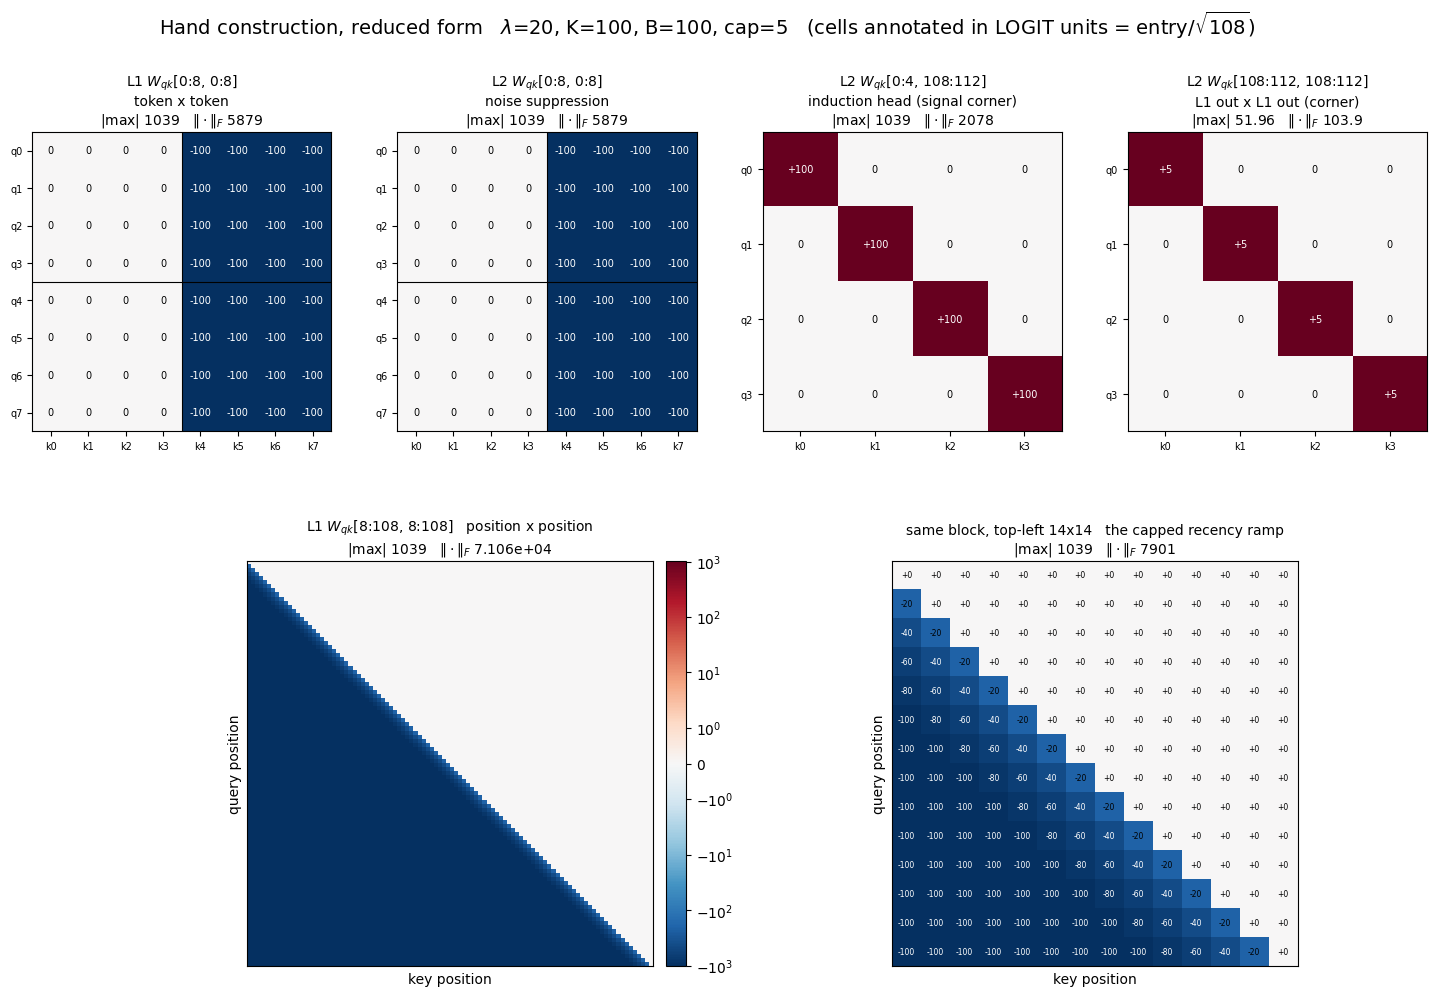

block                                 nonzeros      |max|  distinct nonzero values
L1 $W_{qk}$[0:8, 0:8] token x token         32    1039.23                        1
L2 $W_{qk}$[0:8, 0:8] noise suppression        32    1039.23                        1
L2 $W_{qk}$[0:4, 108:112] induction head (signal corner)         4    1039.23                        1
L2 $W_{qk}$[108:112, 108:112] L1 out x L1 out (corner)         4      51.96                        1
L1 position x position                    4950    1039.23                        5

total nonzeros:  W_qk1 5,382 of 11,664     W_qk2 40 of 46,656


In [3]:
LAM, KIND, BVETO, CAP = 20.0, 100.0, 100.0, 5     # logit-level constants
SDq = D1 ** 0.5                                    # entry = logit * sqrt(108)

def build_construction(lam=LAM, K=KIND, B=BVETO, cap=CAP, drop_col4=True, zero_future=True):
    '''the reduced construction, returned as the two combined W_qk matrices'''
    P1, P2, NF, GAMMA, BIG = K, K / 20., 1.0, -B, -B
    Wq1 = np.eye(D1) * SDq
    T1  = np.zeros((D1, D1))
    T1[Vs:V, :] = BIG                                         # noise-query rows vetoed
    for tq in range(T):
        for tk in range(T):
            dd = tq - tk
            if dd > 0:      T1[V+tk, V+tq] = -lam * min(dd, cap)     # capped recency
            elif dd == 0:   T1[V+tk, V+tq] = 0.0                     # self-veto now lives in
                                                                     # the causal mask, not here
            elif not zero_future: T1[V+tk, V+tq] = -lam * dd         # (masked anyway)
    Wq2 = np.zeros((D1, D2)); Wk2 = np.zeros((D1, D2))
    Wq2[:Vs, :Vs]        = np.eye(Vs) * SDq * P1
    Wq2[:Vs, D1:D1+Vs]   = np.eye(Vs) * SDq * P2
    Wq2[Vs, :V]          = SDq * NF
    Wk2[:V, D1:D1+V]     = np.eye(V)
    Wk2[Vs, Vs:V]        = GAMMA
    C1, C2 = Wq1.T @ T1.T, Wq2.T @ Wk2
    if drop_col4:
        C2[0:V, D1+Vs] = 0.0                                  # the inert artefact column
    # keep only what the run can actually train: the two layer-2 corners are 4x4 now
    keep = np.zeros_like(C2, dtype=bool)
    keep[0:V, 0:V] = True; keep[0:Vs, D1:D1+Vs] = True; keep[D1:D1+Vs, D1:D1+Vs] = True
    C2[~keep] = 0.0
    return C1, C2

K1, K2 = build_construction()
CBLK = [(K1[0:V, 0:V],           'L1 $W_{qk}$[0:8, 0:8]\ntoken x token'),
        (K2[0:V, 0:V],           'L2 $W_{qk}$[0:8, 0:8]\nnoise suppression'),
        (K2[0:Vs, D1:D1+Vs],     'L2 $W_{qk}$[0:4, 108:112]\ninduction head (signal corner)'),
        (K2[D1:D1+Vs, D1:D1+Vs], 'L2 $W_{qk}$[108:112, 108:112]\nL1 out x L1 out (corner)')]

def cheat(ax, A, title, annot=False):
    '''like heat(), but annotates in LOGIT units (entry / sqrt(108)) -- the construction's
       constants are round numbers there, and the raw entries are too wide to print'''
    v = float(np.abs(A).max())
    im = ax.imshow(A, cmap='RdBu_r', interpolation='nearest',
                   norm=SymLogNorm(linthresh=max(v/1e3, 1e-30), linscale=0.6,
                                   vmin=-v, vmax=v, base=10) if v > 0 else None)
    if annot:
        for i in range(A.shape[0]):
            for j in range(A.shape[1]):
                z = A[i, j] / SDq
                ax.text(j, i, '0' if z == 0 else f'{z:+.0f}', ha='center', va='center',
                        fontsize=7, color='white' if abs(A[i, j]) > v/3 else 'black')
        ax.set_xticks(range(A.shape[1])); ax.set_yticks(range(A.shape[0]))
        ax.set_xticklabels([f'k{i}' for i in range(A.shape[1])], fontsize=7)
        ax.set_yticklabels([f'q{i}' for i in range(A.shape[0])], fontsize=7)
        if A.shape[0] > Vs: ax.axhline(Vs - .5, color='k', lw=.8)
        if A.shape[1] > Vs: ax.axvline(Vs - .5, color='k', lw=.8)
    else:
        ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f'{title}\n|max| {np.abs(A).max():.4g}   '
                 f'$\\|\\cdot\\|_F$ {np.linalg.norm(A):.4g}', fontsize=10)
    return im

fig = plt.figure(figsize=(18, 11))
gs = fig.add_gridspec(2, 4, height_ratios=[1, 1.25], hspace=0.32, wspace=0.22)
for j, (A, ttl) in enumerate(CBLK):
    cheat(fig.add_subplot(gs[0, j]), A, ttl, annot=True)

P = K1[V:D1, V:D1]
ax = fig.add_subplot(gs[1, 0:2])
im = cheat(ax, P, 'L1 $W_{qk}$[8:108, 8:108]   position x position')
ax.set_xlabel('key position'); ax.set_ylabel('query position')
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.02)

Z = 14                                         # zoom: the capped ramp is only 5 wide
ax = fig.add_subplot(gs[1, 2:4])
cheat(ax, P[:Z, :Z], f'same block, top-left {Z}x{Z}   the capped recency ramp')
for i in range(Z):
    for j in range(Z):
        ax.text(j, i, f'{P[i, j]/SDq:+.0f}', ha='center', va='center', fontsize=5.5,
                color='white' if abs(P[i, j]) > np.abs(P[:Z, :Z]).max()/3 else 'black')
ax.set_xlabel('key position'); ax.set_ylabel('query position')

fig.suptitle(f'Hand construction, reduced form   '
             f'$\\lambda$={LAM:.0f}, K={KIND:.0f}, B={BVETO:.0f}, cap={CAP}   '
             f'(cells annotated in LOGIT units = entry$/\\sqrt{{108}}$)', fontsize=14)
plt.show()

print(f'{"block":36s} {"nonzeros":>9} {"|max|":>10} {"distinct nonzero values":>24}')
for A, ttl in CBLK + [(K1[V:D1, V:D1], 'L1 position x position')]:
    nz = A != 0
    u = np.unique(np.round(A[nz], 4)) if nz.any() else []
    print(f'{ttl.replace(chr(10), " "):36s} {int(nz.sum()):>9} {np.abs(A).max():>10.2f} {len(u):>24}')
print(f'\ntotal nonzeros:  W_qk1 {int((K1!=0).sum()):,} of {K1.size:,}     '
      f'W_qk2 {int((K2!=0).sum()):,} of {K2.size:,}')

# 3. The construction, centered about zero

Same circuit as §2, same loss, but every block shifted so it is symmetric about zero instead of
running from 0 down to $-100$.

**Why this is free.** Softmax ignores a constant added to every logit in a row. Each shift below
is exactly one of those, so the attention weights — and therefore the cross entropy — are
unchanged:

| block | §2 form | here | shift |
|---|---|---|---|
| L1 token x token | 0 / −100 | **+50 / −50** | +50 |
| L1 position ramp | 0, −20, −40, −60, −80, −100 | **+50, +30, +10, −10, −30** | +70 |
| L2 noise suppression | 0 / −100 | **+50 / −50** | +50 |
| L2 induction 4×4 | +100 diag, 0 off | **+50 diag, −50 off** | −50 |
| L2 L1out 4×4 | +5 diag, 0 off | **+2.5 diag, −2.5 off** | −2.5 |

Measured cost: $+2.8\times10^{-4}$, $+7.4\times10^{-5}$, $0.0$ nats at $\alpha$ = 0.6, 0.8, 1.0 —
float rounding.

**Why it matters.** Gradient descent starts at zero and its solution stays centered
(layer-2 trainable entries: mean $-6.8$, std $34.7$). The §2 construction has mean $-301$ — a
large DC offset that a cosine reads as disagreement even though the two produce identical
attention. Removing it makes the ICL score measure the circuit instead of the gauge:

| | §2 form | centered |
|---|---|---|
| layer 1, $\alpha$=0.6 | 0.9491 | **0.9726** |
| layer 2, $\alpha$=0.6 | 0.5253 | **0.8631** |
| layer 1, $\alpha$=0.8 | 0.9679 | **0.9747** |
| layer 2, $\alpha$=0.8 | 0.5062 | **0.8341** |

(Layer 1's exact value depends on where the ramp is centred — a ramp offset is itself a
per-query constant, so it moves the cosine without moving the loss. With the ramp centred on
its own mean instead of on $+50$, layer 1 reads 0.9814. Layer 2 is unaffected either way.)

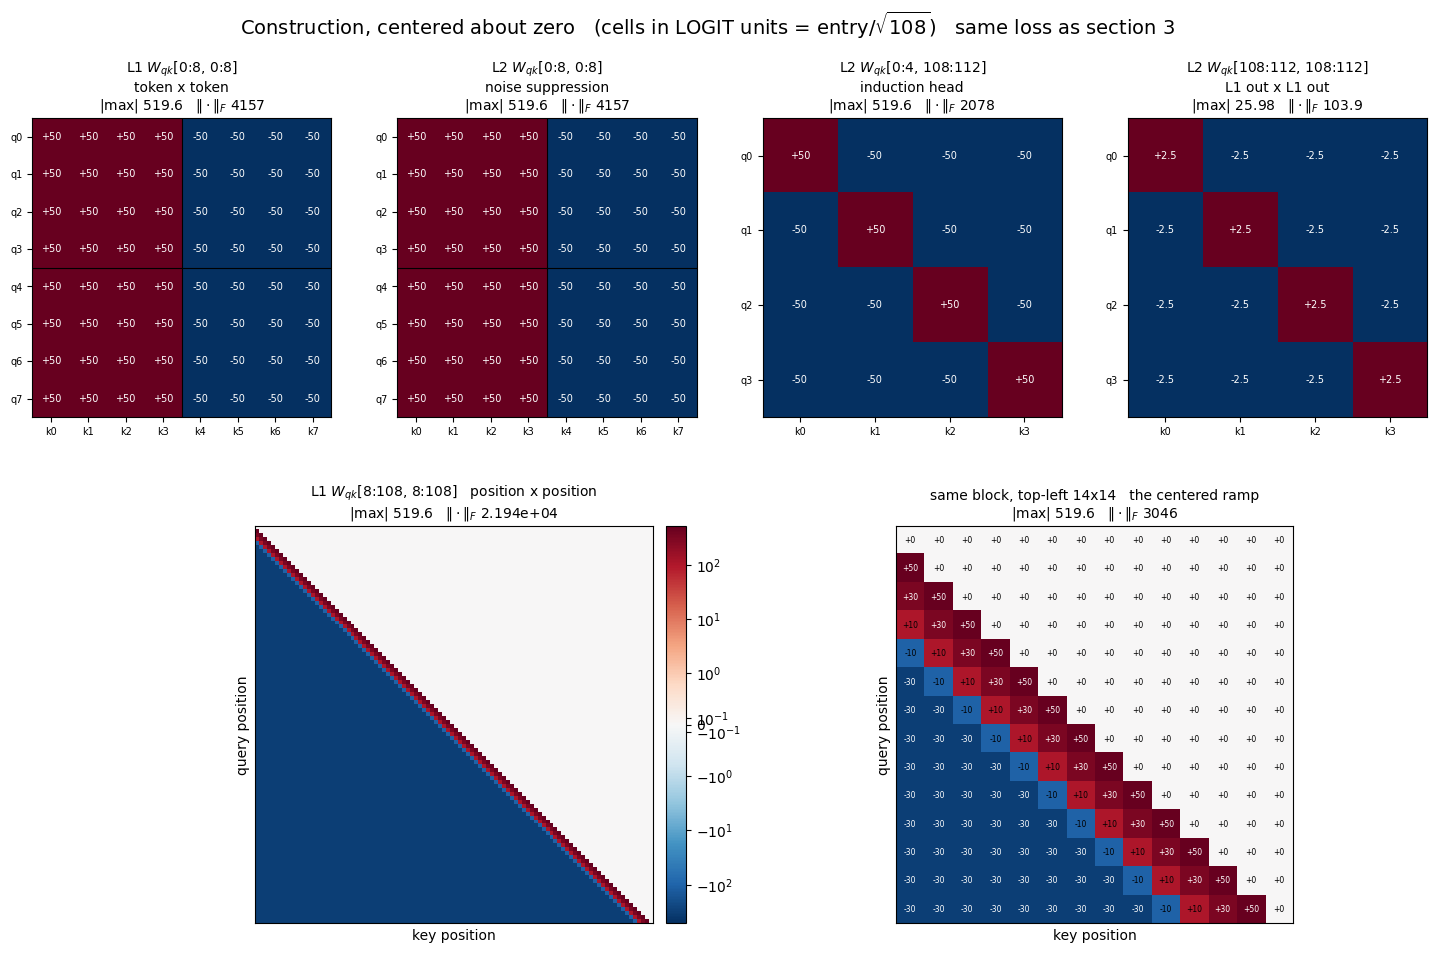

block                               nonzeros     |max|       mean       std
L1 $W_{qk}$[0:8, 0:8] token x token        64    519.62       0.00    519.62
L2 $W_{qk}$[0:8, 0:8] noise suppression        64    519.62       0.00    519.62
L2 $W_{qk}$[0:4, 108:112] induction head        16    519.62    -259.81    450.00
L2 $W_{qk}$[108:112, 108:112] L1 out x L1 out        16     25.98     -12.99     22.50
L1 position x position                  4950    519.62    -133.96    173.82

layer 2, trainable entries only, alpha=0.6:
          GD: mean     -6.81  std    34.72  min    -65.04  max    64.36
    centered: mean    -45.47  std   472.28  min   -519.62  max   519.62


In [5]:
SDq = D1 ** 0.5
LAMc, Kc, Bc, CAPc = 20.0, 100.0, 100.0, 5

def build_centered(lam=LAMc, K=Kc, B=Bc, cap=CAPc):
    '''every block symmetric about zero -- a per-query constant shift of build_construction()'''
    T1 = np.zeros((D1, D1))
    T1[0:Vs, :] = +B / 2                       # signal key tokens  +50
    T1[Vs:V, :] = -B / 2                       # noise  key tokens  -50
    mid = lam + 50.0                           # ramp reads +50 +30 +10 -10 -30
    for tq in range(T):
        for tk in range(T):
            dd = tq - tk
            if dd > 0:
                T1[V+tk, V+tq] = mid - lam * min(dd, cap)
            # dd == 0 stays 0: self-attention is vetoed by the causal mask
    C1 = (np.eye(D1) * SDq).T @ T1.T

    C2 = np.zeros((D2, D2))
    C2[0:V, 0:Vs] = SDq * (+B / 2)             # noise suppression, signal keys  +50
    C2[0:V, Vs:V] = SDq * (-B / 2)             # noise suppression, noise  keys  -50
    C2[0:Vs, D1:D1+Vs] = SDq * (-K / 2)        # induction, off-diagonal  -50
    np.fill_diagonal(C2[0:Vs, D1:D1+Vs], SDq * (+K / 2))          # diagonal  +50
    C2[D1:D1+Vs, D1:D1+Vs] = SDq * (-K / 40)   # L1out x L1out, off-diagonal  -2.5
    np.fill_diagonal(C2[D1:D1+Vs, D1:D1+Vs], SDq * (+K / 40))     # diagonal  +2.5
    return C1, C2

Z1, Z2 = build_centered()
ZBLK = [(Z1[0:V, 0:V],           'L1 $W_{qk}$[0:8, 0:8]\ntoken x token'),
        (Z2[0:V, 0:V],           'L2 $W_{qk}$[0:8, 0:8]\nnoise suppression'),
        (Z2[0:Vs, D1:D1+Vs],     'L2 $W_{qk}$[0:4, 108:112]\ninduction head'),
        (Z2[D1:D1+Vs, D1:D1+Vs], 'L2 $W_{qk}$[108:112, 108:112]\nL1 out x L1 out')]

def zheat(ax, A, title, annot=False):
    '''cells labelled in LOGIT units (entry / sqrt(108)) -- the round numbers of the design'''
    v = float(np.abs(A).max())
    im = ax.imshow(A, cmap='RdBu_r', interpolation='nearest',
                   norm=SymLogNorm(linthresh=max(v/1e3, 1e-30), linscale=0.6,
                                   vmin=-v, vmax=v, base=10) if v > 0 else None)
    if annot:
        for i in range(A.shape[0]):
            for j in range(A.shape[1]):
                z = A[i, j] / SDq
                ax.text(j, i, '0' if z == 0 else f'{z:+g}', ha='center', va='center',
                        fontsize=7, color='white' if abs(A[i, j]) > v/3 else 'black')
        ax.set_xticks(range(A.shape[1])); ax.set_yticks(range(A.shape[0]))
        ax.set_xticklabels([f'k{i}' for i in range(A.shape[1])], fontsize=7)
        ax.set_yticklabels([f'q{i}' for i in range(A.shape[0])], fontsize=7)
        if A.shape[0] > Vs: ax.axhline(Vs - .5, color='k', lw=.8)
        if A.shape[1] > Vs: ax.axvline(Vs - .5, color='k', lw=.8)
    else:
        ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f'{title}\n|max| {np.abs(A).max():.4g}   '
                 f'$\\|\\cdot\\|_F$ {np.linalg.norm(A):.4g}', fontsize=10)
    return im

fig = plt.figure(figsize=(18, 10.5))
gs = fig.add_gridspec(2, 4, height_ratios=[1, 1.3], hspace=0.3, wspace=0.22)
for j, (A, ttl) in enumerate(ZBLK):
    zheat(fig.add_subplot(gs[0, j]), A, ttl, annot=True)

P = Z1[V:D1, V:D1]
ax = fig.add_subplot(gs[1, 0:2])
im = zheat(ax, P, 'L1 $W_{qk}$[8:108, 8:108]   position x position')
ax.set_xlabel('key position'); ax.set_ylabel('query position')
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.02)

Z = 14
ax = fig.add_subplot(gs[1, 2:4])
zheat(ax, P[:Z, :Z], f'same block, top-left {Z}x{Z}   the centered ramp')
for i in range(Z):
    for j in range(Z):
        ax.text(j, i, f'{P[i, j]/SDq:+g}', ha='center', va='center', fontsize=5.5,
                color='white' if abs(P[i, j]) > np.abs(P[:Z, :Z]).max()/3 else 'black')
ax.set_xlabel('key position'); ax.set_ylabel('query position')

fig.suptitle('Construction, centered about zero   '
             r'(cells in LOGIT units = entry$/\sqrt{108}$)   same loss as section 2',
             fontsize=14)
plt.show()

print(f'{"block":34s} {"nonzeros":>9} {"|max|":>9} {"mean":>10} {"std":>9}')
for A, ttl in ZBLK + [(P, 'L1 position x position')]:
    nz = A != 0
    print(f'{ttl.replace(chr(10)," "):34s} {int(nz.sum()):>9} {np.abs(A).max():>9.2f} '
          f'{A.mean():>10.2f} {A.std():>9.2f}')

# side by side with what GD actually holds, on the entries it was allowed to move
mk2 = np.load(f'{RUN}/mask_layer2.W_qk_x_{THR}.npy')
gd2 = np.asarray(W['layer2.W_qk'][-1])
print(f'\nlayer 2, trainable entries only, alpha={THR}:')
print(f'  {"GD":>10}: mean {gd2.mean():>9.2f}  std {gd2.std():>8.2f}  '
      f'min {gd2.min():>9.2f}  max {gd2.max():>8.2f}')
print(f'  {"centered":>10}: mean {Z2[mk2].mean():>9.2f}  std {Z2[mk2].std():>8.2f}  '
      f'min {Z2[mk2].min():>9.2f}  max {Z2[mk2].max():>8.2f}')

# 4. What gradient descent learned


In [ ]:
W1, W2 = final('layer1.W_qk'), final('layer2.W_qk')
# layer 2's induction and state blocks are now the 4x4 SIGNAL CORNER only (96 free entries
# in layer 2, not 192); the position diagonal is gone -- the causal mask vetoes self-attention
BLK = [(W1[0:V, 0:V],             'L1 $W_{qk}$[0:8, 0:8]\ntoken x token'),
       (W2[0:V, 0:V],             'L2 $W_{qk}$[0:8, 0:8]\nnoise suppression'),
       (W2[0:Vs, D1:D1+Vs],       'L2 $W_{qk}$[0:4, 108:112]\ninduction head (signal corner)'),
       (W2[D1:D1+Vs, D1:D1+Vs],   'L2 $W_{qk}$[108:112, 108:112]\nL1 out x L1 out (corner)')]

fig = plt.figure(figsize=(18, 10.5))
gs = fig.add_gridspec(2, 4, height_ratios=[1, 1.3], hspace=0.3, wspace=0.22)
for j, (A, ttl) in enumerate(BLK):
    heat(fig.add_subplot(gs[0, j]), A, ttl, annot=True)

# The position block is SQUARE and imshow keeps aspect 'equal', so spanning it across all four
# columns (gs[1, :]) drew a small square in a very wide axes and left most of the row blank.
# Two columns each: the full block, and a zoom on the corner where the structure actually is.
P = W1[V:D1, V:D1]
ax = fig.add_subplot(gs[1, 0:2])
im = heat(ax, P, 'L1 $W_{qk}$[8:108, 8:108]   position x position')
ax.set_xlabel('key position'); ax.set_ylabel('query position')
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.02)

Z = 14
ax = fig.add_subplot(gs[1, 2:4])
heat(ax, P[:Z, :Z], f'same block, top-left {Z}x{Z}')
for i in range(Z):
    for j in range(Z):
        ax.text(j, i, f'{P[i, j]:.0f}', ha='center', va='center', fontsize=5.5,
                color='white' if abs(P[i, j]) > np.abs(P[:Z, :Z]).max() / 3 else 'black')
ax.set_xlabel('key position'); ax.set_ylabel('query position')

fig.suptitle(f'Final learned $W_{{qk}}$ after step {n-1},  $\\alpha$={THR}   '
             f'(per-panel symlog)', fontsize=14)
plt.show()

# 5. Evolution from the zero init: steps 0 to 50

$\alpha$ = 0.6. **Top row** the weights, **bottom row** the exact full-batch gradient at those
same weights. Frame $k$ shows $W$ before step $k{+}1$ together with $g[k]$, the gradient that
produced that update — so the pair in each frame is cause and effect.

Colour scales are **fixed across all frames** (per panel), so growth is real and not rescaling.

Frame 0 is the zero init: every weight panel is blank, and the layer-1 gradient panel is blank
too — at $W_{qk}=0$ layer 1 has *identically* zero gradient, because $\partial S^2/\partial Z^1$
carries $W^2_{qk}$ as a multiplicative factor. Layer 2's gradient panel is the only thing with
structure at step 0, and it is what starts the whole run.

The four annotated blocks are **row-centered** — each query row's mean subtracted. Adding a
constant to a whole row is an exact softmax invariance, so that offset changes nothing about the
model, and it is what hides the structure: at step 20 the `L1out x L1out` block is $-6.6$ on the
diagonal and $-14.2$ off it, so every cell is negative and the panel reads as uniformly blue.
Centered, the diagonal preference is plain at every frame. The position block is left raw.


In [ ]:
import matplotlib.animation as animation
from IPython.display import HTML, display
plt.rcParams['animation.embed_limit'] = 200

NSTEP = 50                                   # frames 0..NSTEP inclusive
Gr = {p: np.load(f'{RUN}/g_{p}_x_{THR}.npy', mmap_mode='r')[:meta['g_rows_written']]
      for p in meta['params']}

def at(p, k, src=None):
    '''row k of the weight (or gradient) array, put back into its full matrix'''
    a = (src if src is not None else W)[p]
    A = np.zeros(meta['shapes'][p]); A[MK[p]] = a[k]
    return A

# the five trainable blocks: (param, slice, title, annotate?)
CUT = [('layer1.W_qk', (slice(0, V),      slice(0, V)),        'L1 tok x tok',     True),
       ('layer1.W_qk', (slice(V, D1),     slice(V, D1)),       'L1 pos x pos',     False),
       ('layer2.W_qk', (slice(0, V),      slice(0, V)),        'L2 noise suppr.',  True),
       ('layer2.W_qk', (slice(0, Vs),     slice(D1, D1+Vs)),   'L2 induction 4x4', True),
       ('layer2.W_qk', (slice(D1, D1+Vs), slice(D1, D1+Vs)),   'L2 L1out 4x4',     True)]

def rowcenter(st):
    '''subtract each query row's mean. Adding a constant to a whole row is an exact softmax
       invariance, so that offset carries no behaviour -- and it is what hides the structure:
       at step 20 the L1out block is -6.6 on the diagonal and -14.2 off it, so every cell is
       negative and the panel reads as uniformly blue. Centered, the preference is plain.'''
    return st - st.mean(-1, keepdims=True)

# one fixed scale per panel, taken over every frame we will show
Wst = [np.stack([at(p, k)[sl] for k in range(NSTEP + 1)]) for p, sl, _, _ in CUT]
Gst = [np.stack([at(p, k, Gr)[sl] for k in range(NSTEP + 1)]) for p, sl, _, _ in CUT]
# the annotated blocks are row-centered; the position block is left raw (its structure shows)
Wst = [rowcenter(a) if an else a for a, (_, _, _, an) in zip(Wst, CUT)]
Gst = [rowcenter(a) if an else a for a, (_, _, _, an) in zip(Gst, CUT)]
vW = [float(np.abs(a).max()) for a in Wst]
vG = [float(np.abs(a).max()) for a in Gst]

def panel(ax, A, title, vmax, annot):
    v = vmax if vmax > 0 else 1.0
    ax.imshow(A, cmap='RdBu_r', interpolation='nearest',
              norm=SymLogNorm(linthresh=v/1e3, linscale=0.6, vmin=-v, vmax=v, base=10))
    if annot:
        # a 4x4 draws cells twice the size of an 8x8's, so it can carry a much larger font
        fs = 13.0 if A.shape[0] <= Vs else 6.2
        for i in range(A.shape[0]):
            for j in range(A.shape[1]):
                ax.text(j, i, f'{A[i, j]:.3g}', ha='center', va='center', fontsize=fs,
                        fontweight='bold' if i == j else 'normal')
        if A.shape[0] > Vs: ax.axhline(Vs - .5, color='k', lw=.7)
        if A.shape[1] > Vs: ax.axvline(Vs - .5, color='k', lw=.7)
        if A.shape[0] <= Vs:                       # label the 4x4s; there is room for it
            ax.set_xticks(range(A.shape[1])); ax.set_yticks(range(A.shape[0]))
            ax.set_xticklabels([f'k{q}' for q in range(A.shape[1])], fontsize=9)
            ax.set_yticklabels([f'q{q}' for q in range(A.shape[0])], fontsize=9)
        else:
            ax.set_xticks([]); ax.set_yticks([])
    else:
        ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f'{title}\n$\\|\\cdot\\|_F$ {np.linalg.norm(A):.4g}', fontsize=9)

# the loss over the same window, so each frame can be placed in the training curve
HIS = json.load(open(f'{RUN}/metrics_seed0_x_{THR}.json'))['history']
LSTEP = np.array(HIS['step'][:NSTEP + 1])
LTR   = np.array(HIS['train_loss'][:NSTEP + 1])
LTE   = np.array(HIS['test_loss'][:NSTEP + 1])
LFIN  = HIS['test_loss'][-1]

fig = plt.figure(figsize=(4.6 * len(CUT) + 4.6, 10.4))
gs = fig.add_gridspec(2, len(CUT) + 2, width_ratios=[1] * len(CUT) + [0.10, 0.95],
                      wspace=0.10, hspace=0.14)
axes = np.array([[fig.add_subplot(gs[r, c]) for c in range(len(CUT))] for r in range(2)])
ax_loss = fig.add_subplot(gs[:, len(CUT) + 1])
fig.subplots_adjust(top=0.91, bottom=0.05, left=0.03, right=0.985)

def draw_loss(k):
    ax_loss.clear()
    ax_loss.plot(LSTEP, LTR, color='#1f77b4', lw=1.8, label='train')
    ax_loss.plot(LSTEP, LTE, color='#ff7f0e', lw=1.4, ls='--', label='test')
    ax_loss.axvline(k, color='k', lw=1.1, alpha=0.65)
    ax_loss.plot([k], [LTR[k]], 'o', color='#1f77b4', ms=8, zorder=5)
    ax_loss.plot([k], [LTE[k]], 'o', color='#ff7f0e', ms=8, zorder=5)
    ax_loss.annotate(f'step {k}\ntrain {LTR[k]:.5f}\ntest  {LTE[k]:.5f}',
                     xy=(0.96, 0.95), xycoords='axes fraction', ha='right', va='top',
                     fontsize=8.5, family='monospace',
                     bbox=dict(boxstyle='round,pad=0.4', fc='white', ec='0.7', alpha=0.9))
    ax_loss.set_xlim(-0.5, NSTEP + 0.5)
    ax_loss.set_xlabel('optimizer step (= epoch)', fontsize=9)
    ax_loss.set_ylabel('cross entropy', fontsize=9)
    ax_loss.tick_params(labelsize=8)
    ax_loss.set_title(f'loss over these {NSTEP} steps\n'
                      f'(run ends at {LFIN:.5f} after 500)', fontsize=9)
    ax_loss.grid(alpha=0.3); ax_loss.legend(fontsize=8, loc='lower left')

def draw(k):
    for ax in axes.ravel():
        ax.clear()
    for j, (p, sl, ttl, an) in enumerate(CUT):
        tag = ' (row-centered)' if an else ''
        panel(axes[0][j], Wst[j][k], f'W  {ttl}{tag}', vW[j], an)
        panel(axes[1][j], Gst[j][k], f'grad  {ttl}{tag}', vG[j], an)
    draw_loss(k)
    note = '   --  zero init: W all zero, and layer 1 has NO gradient yet' if k == 0 else ''
    fig.suptitle(f'$\\alpha$={THR}   step {k} / {NSTEP}   '
                 f'(top: $W$ before update {k+1};  bottom: $g[{k}]$ at those weights){note}',
                 fontsize=13)
    return []

anim = animation.FuncAnimation(fig, draw, frames=NSTEP + 1, interval=450, blit=False)
plt.close(fig)
display(HTML(anim.to_jshtml()))